# Assignment 3 · Часть 4 — Результаты, интерпретация, воспроизводимость
## Прогнозирование срыва договоров госзакупок в Казахстане

**Автор:** Азиз Абдулин · **Проект:** Tender Risk ML · **Репозиторий:** https://github.com/awzwz/tender-risk-ml

*Русская копия для чтения; сдаётся английская версия. Код и результаты те же, подписи на графиках — на английском.*

Этот ноутбук собирает Assignment 3 вместе: финальная модель, **одна таблица** со всеми моделями ноутбуков 04–06 на
одном и том же периоде test, абляции, показывающие, откуда берётся улучшение, случай утечки, найденный по ходу
работы, объяснения SHAP, результаты по сегментам и всё, что нужно для воспроизведения.

| § | Содержание | Критерий A3 |
|---|---|---|
| 1 | Настройка | — |
| 2 | Финальная модель: признаки, обучение, калибровка | — |
| 3 | Одна таблица для всех экспериментов | 7 · Сравнение всех моделей |
| 4 | Откуда улучшение: абляции и случай утечки | 8 · Интерпретация |
| 5 | Что движет предсказаниями: SHAP | 8 |
| 6 | Результаты по сегментам | 8 |
| 7 | Гипотезы: ожидание против результата | 8 |
| 8 | Воспроизводимость | 9 · Воспроизводимость |
| 9 | Выводы и ограничения | — |

**Как запустить:** после ноутбуков 04, 05a, 05b и 06 (этот ноутбук читает их сохранённые оценки из
`data/predictions/` и настройки из `results/`); `Kernel → Restart & Run All`, ≈ 5 минут.

In [1]:
import json, platform, sys, warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.decomposition import PCA
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_recall_curve, roc_auc_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = 42

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prepare as P
from src.features import load_a3_table, REL, PRICE

PROC, PRED = ROOT / "data" / "processed", ROOT / "data" / "predictions"
FIG = ROOT / "figures"; RES = ROOT / "results" / "a3_07"; RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
df = load_a3_table(ROOT)
df["text"] = df[P.TEXT_FEATURE].fillna("").str.lower().str.strip()
for c in P.CAT_FEATURES: df[c] = df[c].astype("category")
E = np.load(PROC / "emb_rubert-tiny2.npy"); texts = pd.read_parquet(PROC / "emb_texts.parquet").text
tpos = pd.Series(np.arange(len(texts)), index=texts.values)
T = [f"text_pc{k}" for k in range(32)]
df[T] = PCA(32, random_state=SEED).fit(E[tpos[df.loc[df.split == "train", "text"]].to_numpy()]).transform(E[tpos[df.text].to_numpy()])

y = P.TARGET
train, val, test = (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))
y_tr, y_va, y_te = train[y].to_numpy(), val[y].to_numpy(), test[y].to_numpy()
unseen = ~test.text.isin(set(train.text)).to_numpy()

# Workhorse LightGBM for feature experiments (notebook 04: tuning LightGBM brings no gain on these features, and this
# configuration is as good as the best of 50 Optuna trials on validation while being stable and fast)
LGB = dict(learning_rate=0.05)

def fit_lgb(cols, data=None):
    d = train if data is None else data
    m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **LGB)
    m.fit(d[cols], d[y], eval_set=[(val[cols], y_va)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m, m.predict_proba(val[cols])[:, 1], m.predict_proba(test[cols])[:, 1]

rng = np.random.default_rng(SEED); BOOT = [rng.integers(0, len(y_te), len(y_te)) for _ in range(1000)]
def boot_ci(p):
    v = np.array([average_precision_score(y_te[i], p[i]) for i in BOOT]); return np.percentile(v, [2.5, 97.5])
def boot_diff(a, b):
    d = np.array([average_precision_score(y_te[i], a[i]) - average_precision_score(y_te[i], b[i]) for i in BOOT])
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

## 2. Финальная модель

**Признаки (61).** 20 признаков мидтерма; 32 главные компоненты замороженных векторов rubert-tiny2 для названий
лотов (ноутбук 05); 6 признаков истории «заказчик–поставщик» и 3 признака цены к рынку (`src/features.py`) — версии
правил-индикаторов Tender Radar без утечки, отобранные в ресёрче (§11 отчёта о ресёрче).

**Выбор модели на validation.** Три кандидата обучаются на train и сравниваются только по PR-AUC на validation:
простой LightGBM, использованный в экспериментах с признаками (шаг 0,05, ранняя остановка), LightGBM, заново
настроенный на этих 61 признаке через Optuna (30 попыток, пространство поиска из ноутбука 04), и CatBoost с
гиперпараметрами, подобранными в ноутбуке 04 (лучшая модель на 20 признаках).

**Калибровка.** Масштабирование Платта (логистическая регрессия на логите оценки), обученное на validation: оно
превращает оценку в вероятность, не меняя ранжирования.

In [3]:
import optuna
from catboost import CatBoostClassifier, Pool
from sklearn.linear_model import LogisticRegression
optuna.logging.set_verbosity(optuna.logging.WARNING)
FINAL = P.FEATURES + T + REL + PRICE
cands = {}

cands["LightGBM · simple (learning rate 0.05)"] = fit_lgb(FINAL)

def lgb_objective(trial):
    params = dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
                  min_child_samples=trial.suggest_int("min_child_samples", 20, 1000, log=True),
                  colsample_bytree=trial.suggest_float("feature_fraction", 0.4, 1.0),
                  subsample=trial.suggest_float("bagging_fraction", 0.5, 1.0), subsample_freq=trial.suggest_int("bagging_freq", 0, 5),
                  reg_alpha=trial.suggest_float("lambda_l1", 1e-8, 10, log=True), reg_lambda=trial.suggest_float("lambda_l2", 1e-8, 10, log=True),
                  scale_pos_weight=trial.suggest_float("scale_pos_weight", 1, 14))
    m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **params)
    m.fit(train[FINAL], y_tr, eval_set=[(val[FINAL], y_va)], eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
    trial.set_user_attr("params", params)
    return average_precision_score(y_va, m.predict_proba(val[FINAL])[:, 1])
study = optuna.create_study(study_name="lightgbm_final", storage=f"sqlite:///{(RES / 'optuna.db').as_posix()}", direction="maximize",
                            load_if_exists=True, sampler=optuna.samplers.TPESampler(seed=SEED))
todo = 30 - len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
if todo > 0: study.optimize(lgb_objective, n_trials=todo)
m = lgb.LGBMClassifier(n_estimators=5000, random_state=SEED, verbose=-1, **study.best_trial.user_attrs["params"])
m.fit(train[FINAL], y_tr, eval_set=[(val[FINAL], y_va)], eval_metric="average_precision", callbacks=[lgb.early_stopping(100, verbose=False)])
cands["LightGBM · tuned on the final features"] = (m, m.predict_proba(val[FINAL])[:, 1], m.predict_proba(test[FINAL])[:, 1])

cb = json.loads((ROOT / "results" / "a3_04" / "best_params.json").read_text())["CatBoost · tuned"]
as_cat = lambda d: d[FINAL].assign(**{c: d[c].astype(str) for c in P.CAT_FEATURES})
CAT_IDX = [FINAL.index(c) for c in P.CAT_FEATURES]
m = CatBoostClassifier(iterations=3000, eval_metric="PRAUC", random_seed=SEED, verbose=0, thread_count=-1,
                       depth=cb["depth"], learning_rate=cb["learning_rate"], l2_leaf_reg=cb["l2_leaf_reg"], random_strength=cb["random_strength"])
m.fit(as_cat(train), y_tr, cat_features=CAT_IDX, eval_set=(as_cat(val), y_va), early_stopping_rounds=100)
cands["CatBoost · hyper-parameters of notebook 04"] = (m, m.predict_proba(as_cat(val))[:, 1], m.predict_proba(as_cat(test))[:, 1])

selection = pd.DataFrame({k: {"validation PR-AUC": average_precision_score(y_va, v[1]), "test PR-AUC": average_precision_score(y_te, v[2])}
                          for k, v in cands.items()}).T
final_name = selection["validation PR-AUC"].idxmax()
final_model, fin_va, fin_te = cands[final_name]
selection.assign(chosen=lambda d: np.where(d.index == final_name, "✓", ""))

,validation PR-AUC,test PR-AUC,chosen
LightGBM · simple (learning rate 0.05),0.400,0.350,
LightGBM · tuned on the final features,0.386,0.339,
CatBoost · hyper-parameters of notebook 04,0.405,0.364,✓


In [4]:
logit = lambda p: np.log(np.clip(p, 1e-7, 1 - 1e-7) / (1 - np.clip(p, 1e-7, 1 - 1e-7)))
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(fin_va).reshape(-1, 1), y_va)
cal = lambda p: platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]
fin_te_cal = cal(fin_te)
if hasattr(final_model, "booster_"): final_model.booster_.save_model(str(RES / "final_model_lightgbm.txt"))
else: final_model.save_model(str(RES / "final_model_catboost.cbm"))
pd.DataFrame({"id": np.r_[val.id, test.id], "split": ["val"] * len(val) + ["test"] * len(test),
              "score": np.r_[fin_va, fin_te], "probability": np.r_[cal(fin_va), fin_te_cal]}).to_parquet(PRED / "07_final.parquet", index=False)
print(f"final model: {final_name}; {len(FINAL)} features; test PR-AUC {average_precision_score(y_te, fin_te):.3f}, "
      f"ROC-AUC {roc_auc_score(y_te, fin_te):.3f}; mean probability {fin_te_cal.mean():.3f} vs failure rate {y_te.mean():.3f}; "
      f"Brier {brier_score_loss(y_te, fin_te):.4f} -> {brier_score_loss(y_te, fin_te_cal):.4f}")

final model: CatBoost · hyper-parameters of notebook 04; 61 features; test PR-AUC 0.364, ROC-AUC 0.827; mean probability 0.066 vs failure rate 0.066; Brier 0.0508 -> 0.0505


## 3. Одна таблица для всех экспериментов

Каждая строка оценена на одних и тех же 38 981 закупке test (16–31 марта 2024). Порог для F1 выбирается на
validation отдельно для каждой модели. `P@1%` — доля срывов среди 1 % закупок с наибольшей оценкой (389 закупок);
`R@5%` — доля всех срывов, найденных в топ-5 %. Интервал — 95 % бутстрэп-интервал PR-AUC.

In [5]:
def load(name):
    s = pd.read_parquet(PRED / f"{name}.parquet").set_index("id").score
    return s.loc[val.id].to_numpy(), s.loc[test.id].to_numpy()

def top_k(p, k):
    n = int(len(p) * k); idx = np.argsort(-p)[:n]; return y_te[idx].mean(), y_te[idx].sum() / y_te.sum()

def row(group, name, info, pv, pt):
    pr, rc, th = precision_recall_curve(y_va, pv); f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    thr = th[np.argmax(f1[:-1])]; lo, hi = boot_ci(pt)
    return {"group": group, "model": name, "information": info, "test PR-AUC": average_precision_score(y_te, pt),
            "95 % CI": f"[{lo:.3f}, {hi:.3f}]", "ROC-AUC": roc_auc_score(y_te, pt), "F1": f1_score(y_te, pt >= thr),
            "P@1%": top_k(pt, 0.01)[0], "R@5%": top_k(pt, 0.05)[1],
            "PR-AUC unseen texts": average_precision_score(y_te[unseen], pt[unseen])}

R = [row("0 · reference", "No model (failure rate)", "—", np.full(len(y_va), y_tr.mean()), np.full(len(y_te), y_tr.mean()))]
for fam, f in (("Logistic regression", "logistic_regression"), ("Random forest", "random_forest"),
               ("LightGBM", "lightgbm"), ("CatBoost", "catboost")):
    for kind in ("default", "tuned"):
        label = "midterm baseline" if (fam == "Logistic regression" and kind == "default") else kind
        R.append(row("1 · model comparison (04)", f"{fam} · {label}", "20 features", *load(f"04_{f}_{kind}")))
R.append(row("2 · text alone (05)", "TF-IDF + logistic regression", "lot names", *load("05b_tf_idf___logistic_regression")))
for key in ("rubert-tiny2", "multilingual-e5-small", "rubert-base-cased"):
    R.append(row("2 · text alone (05)", f"frozen {key} + linear probe", "lot names", *load(f"05_probe_{key}")))
R.append(row("2 · text alone (05)", "fine-tuned rubert-tiny2", "lot names", *load("05_rubert_finetuned")))
for f in sorted(PRED.glob("05b_*.parquet")):
    if "tf_idf" in f.stem or "20_features" in f.stem: continue
    R.append(row("3 · table + text (05)", f.stem.replace("05b_", "").replace("_", " "), "20 features + text", *load(f.stem)))
R.append(row("4 · LLM (06)", "Qwen2.5-1.5B + QLoRA, 40 k rows", "card: 20 features + history + price + lot names", *load("06_llm_qlora")))
R.append(row("4 · LLM (06)", "simple LightGBM + LLM ensemble", "61 features + LLM", *load("06_blend_lgb_llm")))
R.append(row("5 · final", "Final model", f"{final_name}; 20 features + text + history + price", fin_va, fin_te))
# the final model averaged with the LLM (logit scale, weight chosen on validation as in notebook 06)
llm_va, llm_te = load("06_llm_qlora")
weights = np.linspace(0, 1, 21)
alpha = float(weights[np.argmax([average_precision_score(y_va, (1 - a) * logit(fin_va) + a * logit(llm_va)) for a in weights])])
ens_va, ens_te = (1 - alpha) * logit(fin_va) + alpha * logit(llm_va), (1 - alpha) * logit(fin_te) + alpha * logit(llm_te)
R.append(row("5 · final", "Final model + LLM ensemble", f"LLM weight {alpha:.2f} chosen on validation", ens_va, ens_te))
table = pd.DataFrame(R).set_index(["group", "model"])
table.to_csv(RES / "all_models_test.csv")
table

information  test PR-AUC  \
group                     model                                                                                                                                             
0 · reference             No model (failure rate)                                                                                                          —        0.066   
1 · model comparison (04) Logistic regression · midterm baseline                                                                                 20 features        0.262   
                          Logistic regression · tuned                                                                                            20 features        0.280   
                          Random forest · default                                                                                                20 features        0.249   
                          Random forest · tuned                                                                                                  20 features        0.290   
                          LightGBM · default                                                                                                     20 features        0.303   
                          LightGBM · tuned                                                                                                       20 features        0.304   
                          CatBoost · default                                                                                                     20 features        0.288   
                          CatBoost · tuned                                                                                                       20 features        0.311   
2 · text alone (05)       TF-IDF + logistic regression                                                                                             lot names        0.153   
                          frozen rubert-tiny2 + linear probe                                                                                       lot names        0.125   
                          frozen multilingual-e5-small + linear probe                                                                              lot names        0.131   
                          frozen rubert-base-cased + linear probe                                                                                  lot names        0.133   
                          fine-tuned rubert-tiny2                                                                                                  lot names        0.156   
3 · table + text (05)     32 components of frozen multilingual e5 small                                                                   20 features + text        0.339   
                          32 components of frozen rubert base cased                                                                       20 features + text        0.336   
                          32 components of frozen rubert tiny2                                                                            20 features + text        0.347   
                          blend  tabular   fine tuned text  weight 0 30 on validation                                                     20 features + text        0.321   
                          fine tuned text score  stacking                                                                                 20 features + text        0.333   
4 · LLM (06)              Qwen2.5-1.5B + QLoRA, 40 k rows                                                    card: 20 features + history + price + lot names        0.322   
                          simple LightGBM + LLM ensemble                                                                                   61 features + LLM        0.358   
5 · final                 Final model                                                  CatBoost · hyper-parameters of notebook 04; 20 features + text + h...        0.

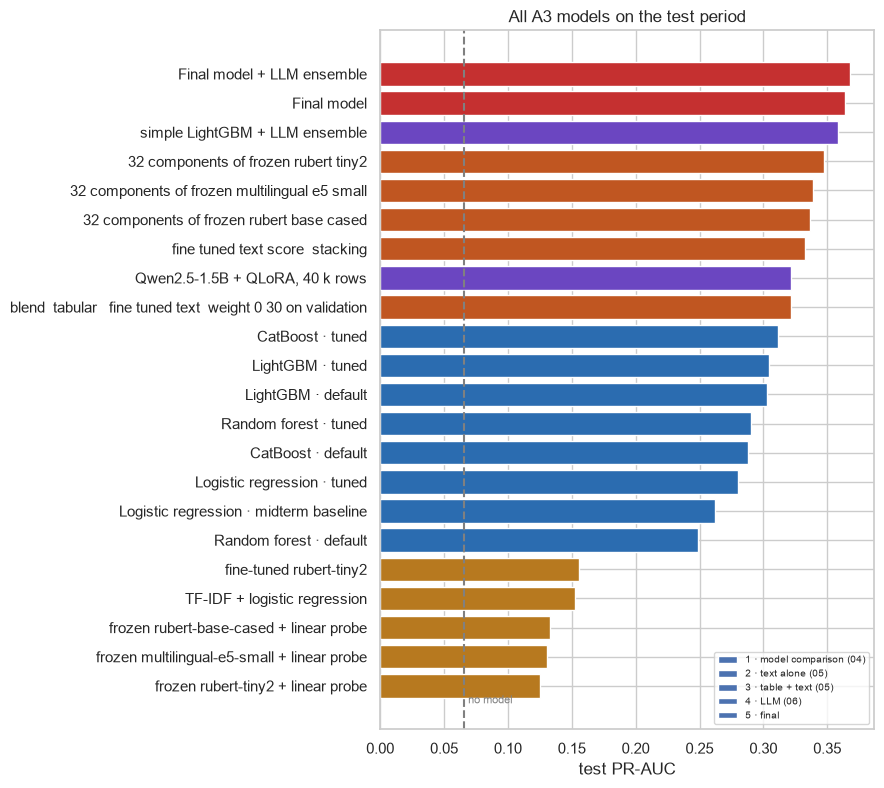

In [6]:
plot = table.reset_index()
plot = plot[plot.group != "0 · reference"].sort_values("test PR-AUC")
fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot) + 1))
palette = {"1 · model comparison (04)": "#2b6cb0", "2 · text alone (05)": "#b7791f", "3 · table + text (05)": "#c05621",
           "4 · LLM (06)": "#6b46c1", "5 · final": "#c53030"}
ax.barh(plot.model, plot["test PR-AUC"], color=[palette[g] for g in plot.group])
ax.axvline(y_te.mean(), ls="--", color="grey"); ax.text(y_te.mean() + 0.003, -0.6, "no model", fontsize=8, color="grey")
for gname, c in palette.items(): ax.barh([], [], color=c, label=gname)
ax.set(xlabel="test PR-AUC", title="All A3 models on the test period"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "a3_07_all_models.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Откуда берётся улучшение

### 4.1 Абляции финальной модели
Каждая группа признаков по очереди убирается, и модель переобучается с теми же настройками (простой LightGBM, чтобы
менялись только признаки). Разница с полным набором признаков, с парным бутстрэп-интервалом, — вклад этой группы
*при наличии всех остальных*.

In [7]:
# ablations use the simple LightGBM (the same configuration for every variant, so that only the features differ)
abl = {"final model (all groups)": (FINAL, cands["LightGBM · simple (learning rate 0.05)"][2])}
for label, drop in (("− text components", T), ("− customer–supplier history", REL), ("− price vs market", PRICE),
                    ("− history and price", REL + PRICE), ("only the 20 midterm features", T + REL + PRICE)):
    cols = [c for c in FINAL if c not in drop]
    abl[label] = (cols, fit_lgb(cols)[2])
abl_rows = {}
for label, (cols, p) in abl.items():
    m, lo, hi = boot_diff(p, abl["final model (all groups)"][1]) if label != "final model (all groups)" else (0, 0, 0)
    abl_rows[label] = {"features": len(cols), "test PR-AUC": average_precision_score(y_te, p),
                       "change vs final": "" if label.startswith("final") else f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]"}
ablation = pd.DataFrame(abl_rows).T; ablation.to_csv(RES / "ablation.csv"); ablation

,features,test PR-AUC,change vs final
final model (all groups),61,0.350,
− text components,29,0.325,"-0.025 [-0.034, -0.016]"
− customer–supplier history,55,0.353,"+0.004 [-0.002, +0.010]"
− price vs market,58,0.349,"-0.001 [-0.006, +0.004]"
− history and price,52,0.347,"-0.003 [-0.009, +0.004]"
only the 20 midterm features,20,0.311,"-0.039 [-0.051, -0.027]"


### 4.2 Случай утечки: победитель, взятый из договора

Ранняя версия ресёрча добавляла три признака «активности победителя» (заявки победителя за предыдущие 30 дней, ИП
или нет), и они выглядели как третий по важности источник информации (+0,025 PR-AUC). Победитель брался из
**таблицы договоров**. Проверка самых сильных предсказаний выявила проблему: если победитель отказывается подписывать,
договор уходит другому участнику или заключается вне конкурса, поэтому *кто подписал договор* — отчасти уже исход. В
закупках с заявками подписант договора даже не подавал заявку в 27 % успешных и 63 % сорвавшихся закупок.

Таблица повторяет эксперимент с тремя определениями победителя. До исхода известно только последнее: поставщик,
указанный в объявлении (закупка из одного источника), или участник с минимальной ценой (с процедурным правилом при
ничьей — при равных ценах побеждает более ранняя заявка).

In [8]:
import duckdb
con = duckdb.connect(); con.sql("SET enable_progress_bar = false"); r = (ROOT / "data" / "raw").as_posix()
con.sql(f"CREATE VIEW mt AS SELECT id, publish_dt FROM read_parquet('{(PROC / 'model_table.parquet').as_posix()}')")
con.sql(f"CREATE TABLE app AS SELECT buyId AS buy_id, supplierBinIin AS sup, CAST(dateApply AS TIMESTAMP) AS dt FROM read_parquet('{r}/trd_app.parquet')")
con.sql(f"CREATE TABLE ctr AS SELECT trdBuyId AS id, arg_min(supplierBiin, rootId) AS first_sup, min(supplierBiin) AS min_sup FROM read_parquet('{r}/contracts.parquet') GROUP BY 1")
from src.features import winners
honest = winners(ROOT / "data" / "raw").rename(columns={"winner": "honest_sup"})[["id", "honest_sup"]]
con.register("honest", honest)
def winner_feats(col):
    return con.sql(f'''
        WITH w AS (SELECT m.id, m.publish_dt AS t, {col} AS sup FROM mt m LEFT JOIN ctr USING (id) LEFT JOIN honest USING (id)),
        h AS (SELECT w.id, count(a.sup) AS bids_30d, count(DISTINCT a.buy_id) AS procs_30d
              FROM w LEFT JOIN app a ON a.sup = w.sup AND a.dt < w.t AND a.dt >= w.t - INTERVAL 30 DAY GROUP BY 1)
        SELECT w.id, (substr(w.sup, 5, 1) IN ('0','1','2','3'))::INT AS individual, h.bids_30d, h.procs_30d
        FROM w JOIN h USING (id)''').df()
leak_rows = {}
base_m, _, base_te = fit_lgb(P.FEATURES)
for label, col in (("winner = min(BIN) among contracts (research v2)", "ctr.min_sup"),
                   ("winner = supplier of the first contract", "ctr.first_sup"),
                   ("winner from announcement / lowest bid (leak-free)", "honest.honest_sup")):
    wf = winner_feats(col)
    for d in (train, val, test):
        d[["w_ind", "w_bids", "w_procs"]] = wf.set_index("id").loc[d.id, ["individual", "bids_30d", "procs_30d"]].astype(float).to_numpy()
    _, _, p = fit_lgb(P.FEATURES + ["w_ind", "w_bids", "w_procs"])
    m, lo, hi = boot_diff(p, base_te)
    leak_rows[label] = {"test PR-AUC": average_precision_score(y_te, p), "gain over 20 features": f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]"}
leak = pd.DataFrame(leak_rows).T; leak.to_csv(RES / "leakage_winner.csv"); leak

,test PR-AUC,gain over 20 features
winner = min(BIN) among contracts (research v2),0.336,"+0.025 [+0.018, +0.031]"
winner = supplier of the first contract,0.352,"+0.041 [+0.034, +0.048]"
winner from announcement / lowest bid (leak-free),0.308,"-0.003 [-0.008, +0.002]"


«Прирост» исчезает при определении победителя без утечки. Урок для отчёта: признак, который выглядит слишком хорошо,
надо проследить до момента, когда его значение становится известно, — здесь проблема была не в самом признаке (даты
заявок были правильные), а в **связке** между записями (какой поставщик считается «победителем»), созданной уже
после исхода.

## 5. Что движет предсказаниями: SHAP

Значения SHAP раскладывают каждое предсказание (логарифм шансов срыва) на аддитивные вклады признаков. Они
вычислены точным алгоритмом TreeSHAP, встроенным в библиотеку бустинга (LightGBM `pred_contrib=True` или CatBoost
`ShapValues` — тот же алгоритм, что `shap.TreeExplainer`, с поддержкой категориальных разбиений), на 5 000 закупок
test. 32 текстовые компоненты суммируются в один вклад «текст лотов», поскольку отдельная компонента смысла не имеет.

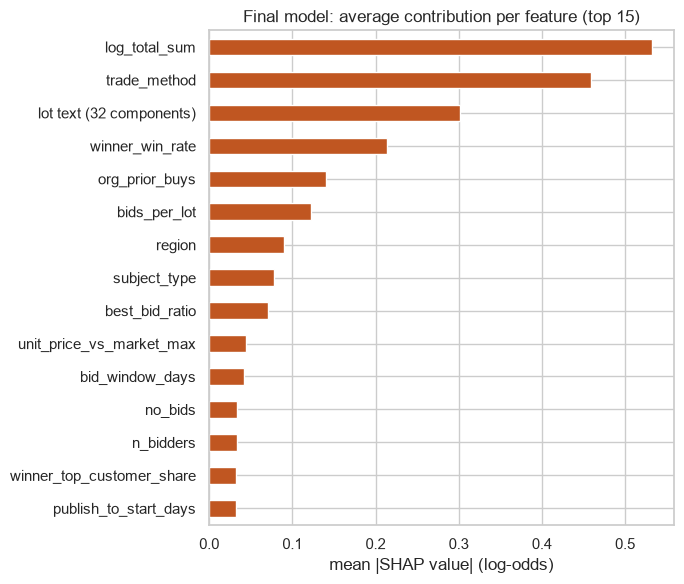

,mean |SHAP|
log_total_sum,0.532
trade_method,0.459
lot text (32 components),0.302
winner_win_rate,0.213
org_prior_buys,0.140
bids_per_lot,0.122
region,0.090
subject_type,0.078
best_bid_ratio,0.071
unit_price_vs_market_max,0.045


In [9]:
sample = test.sample(5000, random_state=SEED)
if hasattr(final_model, "booster_"):                                          # LightGBM
    contrib = final_model.booster_.predict(sample[FINAL], pred_contrib=True)  # last column = expected value
    raw = final_model.booster_.predict(sample[FINAL], raw_score=True)
else:                                                                         # CatBoost
    pool = Pool(as_cat(sample), cat_features=CAT_IDX)
    contrib = final_model.get_feature_importance(pool, type="ShapValues")
    raw = final_model.predict(pool, prediction_type="RawFormulaVal")
assert np.allclose(contrib.sum(1), raw, atol=1e-4)                            # contributions add up to the prediction
S = pd.DataFrame(contrib[:, :-1], columns=FINAL, index=sample.index)
S["lot text (32 components)"] = S[T].sum(axis=1); S = S.drop(columns=T)
mean_abs = S.abs().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 6))
mean_abs.head(15)[::-1].plot.barh(ax=ax, color="#c05621")
ax.set(xlabel="mean |SHAP value| (log-odds)", title="Final model: average contribution per feature (top 15)")
plt.tight_layout(); plt.savefig(FIG / "a3_07_shap_importance.png", dpi=150, bbox_inches="tight"); plt.show()
mean_abs.head(15).to_frame("mean |SHAP|")

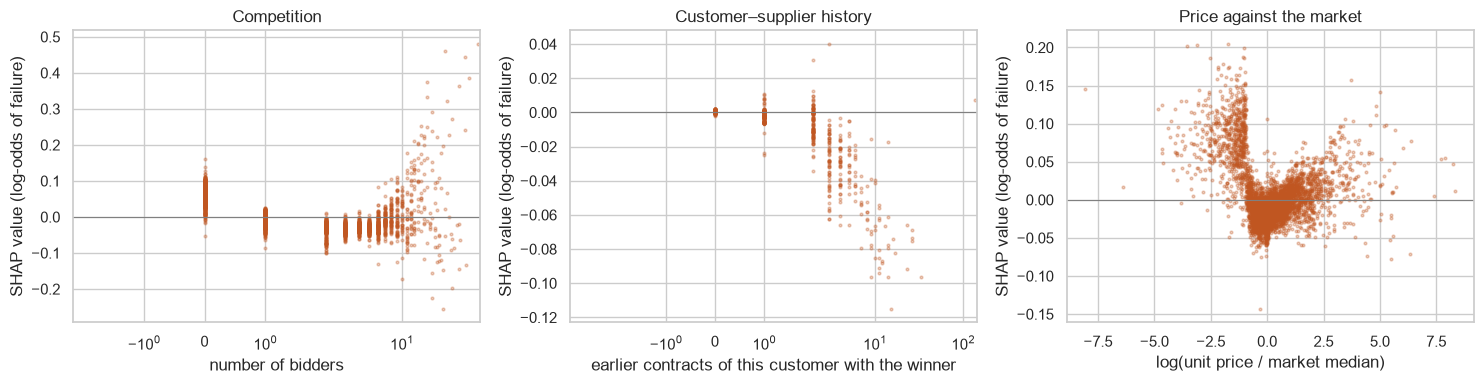

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, xlab in zip(ax, ["n_bidders", "pair_prior_contracts", "unit_price_vs_market"],
                        ["number of bidders", "earlier contracts of this customer with the winner", "log(unit price / market median)"]):
    x = sample[col].astype(float)
    a.scatter(x, S[col], s=4, alpha=0.3, color="#c05621")
    a.axhline(0, color="grey", lw=0.8); a.set(xlabel=xlab, ylabel="SHAP value (log-odds of failure)")
    if col != "unit_price_vs_market": a.set_xscale("symlog")
ax[0].set_title("Competition"); ax[1].set_title("Customer–supplier history"); ax[2].set_title("Price against the market")
plt.tight_layout(); plt.savefig(FIG / "a3_07_shap_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Результаты по сегментам

PR-AUC зависит от доли положительных, поэтому сегменты с разной долей срывов нельзя сравнивать по одному PR-AUC.
Таблица показывает **подъём (lift)**: PR-AUC, делённый на долю срывов в сегменте (1 = не лучше случайного внутри
сегмента), и ROC-AUC, который от доли не зависит.

In [11]:
base = pd.read_parquet(PRED / "04_logistic_regression_default.parquet").set_index("id").score.loc[test.id].to_numpy()
seg = test.assign(value_quartile=pd.qcut(test.log_total_sum, 4, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4 (largest)"]),
                  text_seen=np.where(unseen, "unseen text", "seen text"))
rows = []
for col in ("trade_method", "value_quartile", "text_seen"):
    for level, g in seg.groupby(col, observed=True):
        if g[y].sum() < 30: continue
        i = g.index.to_numpy(); rate = g[y].mean()
        rows.append({"segment": f"{col} = {level}", "procurements": len(g), "failure rate": rate,
                     "lift, baseline": average_precision_score(g[y], base[i]) / rate,
                     "lift, final": average_precision_score(g[y], fin_te[i]) / rate,
                     "ROC-AUC, baseline": roc_auc_score(g[y], base[i]), "ROC-AUC, final": roc_auc_score(g[y], fin_te[i])})
segments = pd.DataFrame(rows).set_index("segment"); segments.to_csv(RES / "segments.csv"); segments

,procurements,failure rate,"lift, baseline","lift, final","ROC-AUC, baseline","ROC-AUC, final"
segment,,,,,,
trade_method = Open tender,1257,0.068,1.519,2.189,0.625,0.713
trade_method = Other,714,0.056,1.780,3.197,0.521,0.625
trade_method = Request for quotations,22870,0.091,3.792,4.508,0.801,0.826
trade_method = Single source after failed tender,11760,0.020,2.205,8.016,0.694,0.793
trade_method = Tender with scoring system,624,0.059,1.267,1.160,0.558,0.551
trade_method = Tender: school food (goods),903,0.055,1.478,1.495,0.544,0.589
value_quartile = Q1 (cheapest),9746,0.015,2.302,3.602,0.694,0.744
value_quartile = Q2,9745,0.033,1.991,2.958,0.656,0.730
value_quartile = Q3,9745,0.063,2.017,2.763,0.675,0.720


## 7. Гипотезы: ожидание против результата

Гипотезы записаны в плане ресёрча до запуска ноутбуков (результаты пилотов — в скобках там).

In [12]:
t = table["test PR-AUC"]
g = lambda name: t.xs(name, level="model").iloc[0]
H = pd.DataFrame([
    {"hypothesis": "H4 · the model family matters more than hyper-parameter tuning",
     "evidence": f"baseline {g('Logistic regression · midterm baseline'):.3f} → LightGBM default {g('LightGBM · default'):.3f} → tuned {g('LightGBM · tuned'):.3f}",
     "verdict": "supported: changing the family gives +0.04–0.05; tuning gives 0 to +0.04 depending on how far the defaults are from the optimum"},
    {"hypothesis": "H5 · new information matters more than tuning",
     "evidence": f"same CatBoost configuration: 20 features {g('CatBoost · tuned'):.3f} → + text, history, price {g('Final model'):.3f}; "
                 f"tuning on the 20 features: {g('CatBoost · default'):.3f} → {g('CatBoost · tuned'):.3f}",
     "verdict": "supported: new information (+0.053) is worth twice the tuning gain (+0.023) of the same model"},
    {"hypothesis": "H6 · text is useful together with the table, not alone",
     "evidence": f"best text-only model {table.xs('2 · text alone (05)')['test PR-AUC'].max():.3f} vs table + text {table.xs('3 · table + text (05)')['test PR-AUC'].max():.3f}",
     "verdict": "supported: text alone is half as good as the table, but it is the largest addition to it"},
    {"hypothesis": "H7 · fine-tuning makes text a stronger signal than TF-IDF",
     "evidence": f"TF-IDF {g('TF-IDF + logistic regression'):.3f} vs fine-tuned {g('fine-tuned rubert-tiny2'):.3f}; unseen texts "
                 f"{table.xs('TF-IDF + logistic regression', level='model')['PR-AUC unseen texts'].iloc[0]:.3f} vs "
                 f"{table.xs('fine-tuned rubert-tiny2', level='model')['PR-AUC unseen texts'].iloc[0]:.3f}",
     "verdict": "partly: a tie overall, a clear gain on unseen texts; as a feature inside the table frozen components are better"},
    {"hypothesis": "H8 · the LLM is below boosting on the full train set but helps in an ensemble",
     "evidence": f"LLM {g('Qwen2.5-1.5B + QLoRA, 40 k rows'):.3f}; final model {g('Final model'):.3f}; final + LLM {g('Final model + LLM ensemble'):.3f} "
                 f"({boot_diff(ens_te, fin_te)[0]:+.3f} [{boot_diff(ens_te, fin_te)[1]:+.3f}, {boot_diff(ens_te, fin_te)[2]:+.3f}])",
     "verdict": "supported: weaker alone, a small but significant gain in an ensemble"},
    {"hypothesis": "H9 · calibration fixes the probabilities without changing the ranking",
     "evidence": f"final model Brier {brier_score_loss(y_te, fin_te):.4f} → {brier_score_loss(y_te, fin_te_cal):.4f}; "
                 f"PR-AUC {average_precision_score(y_te, fin_te):.3f} → {average_precision_score(y_te, fin_te_cal):.3f}",
     "verdict": "supported (notebook 04: baseline Brier 0.200 → 0.055); the final model is trained without class weights and is already calibrated"},
]).set_index("hypothesis")
with pd.option_context("display.max_colwidth", 200):
    display(H)

,evidence,verdict
hypothesis,,
H4 · the model family matters more than hyper-parameter tuning,baseline 0.262 → LightGBM default 0.303 → tuned 0.304,supported: changing the family gives +0.04–0.05; tuning gives 0 to +0.04 depending on how far the defaults are from the optimum
H5 · new information matters more than tuning,"same CatBoost configuration: 20 features 0.311 → + text, history, price 0.364; tuning on the 20 features: 0.288 → 0.311",supported: new information (+0.053) is worth twice the tuning gain (+0.023) of the same model
"H6 · text is useful together with the table, not alone",best text-only model 0.156 vs table + text 0.347,"supported: text alone is half as good as the table, but it is the largest addition to it"
H7 · fine-tuning makes text a stronger signal than TF-IDF,TF-IDF 0.153 vs fine-tuned 0.156; unseen texts 0.200 vs 0.228,"partly: a tie overall, a clear gain on unseen texts; as a feature inside the table frozen components are better"
H8 · the LLM is below boosting on the full train set but helps in an ensemble,"LLM 0.322; final model 0.364; final + LLM 0.368 (+0.004 [+0.001, +0.007])","supported: weaker alone, a small but significant gain in an ensemble"
H9 · calibration fixes the probabilities without changing the ranking,final model Brier 0.0508 → 0.0505; PR-AUC 0.364 → 0.364,supported (notebook 04: baseline Brier 0.200 → 0.055); the final model is trained without class weights and is already calibrated


## 8. Воспроизводимость

* **Данные**: сырой снимок (OWS API, закупки, опубликованные в I квартале 2024) и таблица для моделей опубликованы
  как релиз GitHub `data-v1`; каждый ноутбук скачивает то, что ему нужно. Сборщик `src/collect.py` воссоздаёт снимок
  при наличии API-токена.
* **Код**: признаки в `src/prepare.py` и `src/features.py`; ноутбуки генерируются из `notebooks/build_*.py`; скрипт LLM
  — `kaggle/06_llm_qlora/train_qlora.py`.
* **Случайность**: зерно 42 везде (дообучение также с зёрнами 43, 44); детерминированное разрешение ничьих в
  определении победителя. Обучение на видеокарте (05a, 06) не воспроизводится бит в бит на другом железе; разница
  появляется в третьем знаке.
* **Сохранённые настройки и результаты**: исследования Optuna (`results/a3_04/optuna.db`), выбранные конфигурации
  (`results/a3_04/best_params.json`, `results/a3_05/finetune_choice.json`), журнал обучения и оценки LLM
  (`results/a3_06/`), финальная модель (`results/a3_07/`) и все таблицы в CSV.

In [13]:
libs = ["numpy", "pandas", "scikit-learn", "lightgbm", "catboost", "optuna", "duckdb", "torch", "transformers", "peft"]
env = {"python": platform.python_version(), "platform": platform.platform()}
for l in libs:
    try: env[l] = version(l)
    except Exception: env[l] = "not installed"
kaggle_log = json.loads((ROOT / "results" / "a3_06" / "train_log.json").read_text())
env["LLM run"] = f"Kaggle, {kaggle_log['gpu']}"
(RES / "environment.json").write_text(json.dumps(env, indent=2)); pd.Series(env).to_frame("version")

,version
python,3.14.5
platform,macOS-26.7.1-arm64-arm-64bit-Mach-O
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
lightgbm,4.7.0
catboost,1.2.10
optuna,5.0.0
duckdb,1.5.6
torch,2.14.1


## 9. Выводы и ограничения

1. **Финальная модель.** CatBoost (гиперпараметры подобраны в ноутбуке 04) на 61 признаке — 20 признаков мидтерма,
   32 компоненты текста лотов, 9 признаков «заказчик–поставщик» и цены без утечки — даёт PR-AUC на test **0,364**
   (95 % интервал [0,343; 0,385]) против **0,262** у baseline мидтерма, ROC-AUC 0,827 против 0,792, и её
   вероятности откалиброваны (среднее 0,066 = реальная доля срывов). Для проверяющего, который может проверить 1 %
   закупок — около 390 за эти две недели, — это **≈ 280 найденных сорванных договоров вместо ≈ 196** с моделью
   мидтерма и ≈ 26 при случайном выборе.
2. **Откуда прирост.** Два примерно равных шага: семейство модели (линейная → настроенный CatBoost на тех же 20
   признаках, +0,049) и новая информация (тот же CatBoost с текстом, историей и ценой, +0,053). Подбор
   гиперпараметров поверх хорошей модели вышел на плато (LightGBM: +0,001; повторная настройка LightGBM на 61
   признаке не дотянула даже до простой конфигурации на validation). Абляции показывают, что почти вся новая
   информация — это **текст лотов** (−0,025 без него); история «заказчик–поставщик» и цена, хотя по отдельности
   предсказательны, ничего не добавляют при наличии текста.
3. **Текст: transfer learning против fine-tuning против LLM.** Замороженные векторы кодировщика слабы сами по себе
   (ниже TF-IDF), но это лучший способ передать текст табличной модели. Дообучение даёт лучшую модель одного текста
   на названиях, не встречавшихся при обучении (0,228 против 0,200 у TF-IDF). LLM на 1,5 млрд параметров с QLoRA,
   читающая всю карточку закупки, выше любой модели на 20 признаках (0,322), но ниже бустинга с той же информацией;
   в среднем с финальной моделью она добавляет небольшие, статистически значимые +0,004 (0,368) — ценой 3,5
   GPU-часов.
4. **Урок про утечку.** Семейство признаков, выглядевшее третьим по важности источником информации, оказалось
   утечкой через *связку* между записями (подписант договора как «победитель»). Её нашли, потому что прирост
   выглядел слишком большим и верх ранжированного списка проверили вручную; с определением победителя без утечки
   прирост равен нулю.
5. **Где модель помогает больше всего.** По сегментам самые большие улучшения относительно baseline — у закупок из
   одного источника после несостоявшейся закупки (подъём 2,2 → 8,0) и у самой дешёвой четверти закупок (подъём
   2,3 → 3,6) — самого слабого сегмента модели мидтерма. Конкурсы с рейтингово-балльной системой остаются трудными
   (подъём ≈ 1,2, всего 624 закупки в test).

Ограничения, которые относятся ко всем цифрам этого ноутбука:

* **Один квартал, одна тестовая половина месяца.** Модели обучены на январе–феврале 2024 и проверены на второй
  половине марта. Закупки в конце года (декабрь), со спешкой освоить бюджет, могут срываться чаще и по другим
  причинам; модель их не видела.
* **Метка — итоговый статус, записанный на портале.** Расторжения «по соглашению сторон» включают безобидные случаи
  (строгая метка без них сохранена в данных как `contract_failed_strict`).
* **Только информация, известная в момент выбора победителя.** Это исключает самые сильные сигналы, которые
  использовал Tender Radar (исполнение договора, платежи, штрафы): они и есть сам исход.